In [17]:
!pip install -q skorch imbalanced-learn

import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
os.makedirs("/kaggle/working/images", exist_ok=True)
print("Device :", device)

Device : cuda


In [18]:
df = pd.read_csv("/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv")
print(df.shape); df.head()

(10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [19]:
df.info(); print(df.isna().sum(), "doublons :", df.duplicated().sum())
print(df["Failure Type"].value_counts())

# Incohérence réelle : Target=1 mais "No Failure"
bad = (df.Target == 1) & (df["Failure Type"] == "No Failure")
print(bad.sum(), "lignes incohérentes supprimées")
df = df[~bad]

df = df.drop(columns=["UDI", "Product ID", "Target"])
df.columns = ["Type","air_temp","proc_temp","rpm","torque","tool_wear","failure"]
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque

,Type,air_temp,proc_temp,rpm,torque,tool_wear,failure
0,M,298.1,308.6,1551,42.8,0,No Failure
1,L,298.2,308.7,1408,46.3,3,No Failure
2,L,298.1,308.5,1498,49.4,5,No Failure
3,L,298.2,308.6,1433,39.5,7,No Failure
4,L,298.2,308.7,1408,40.0,9,No Failure


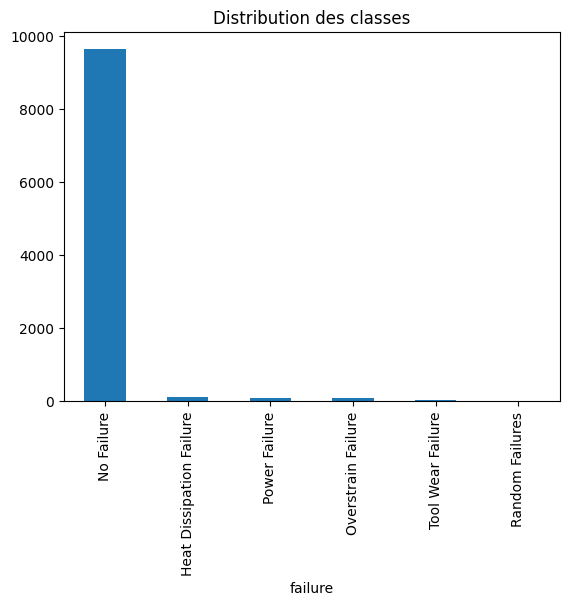

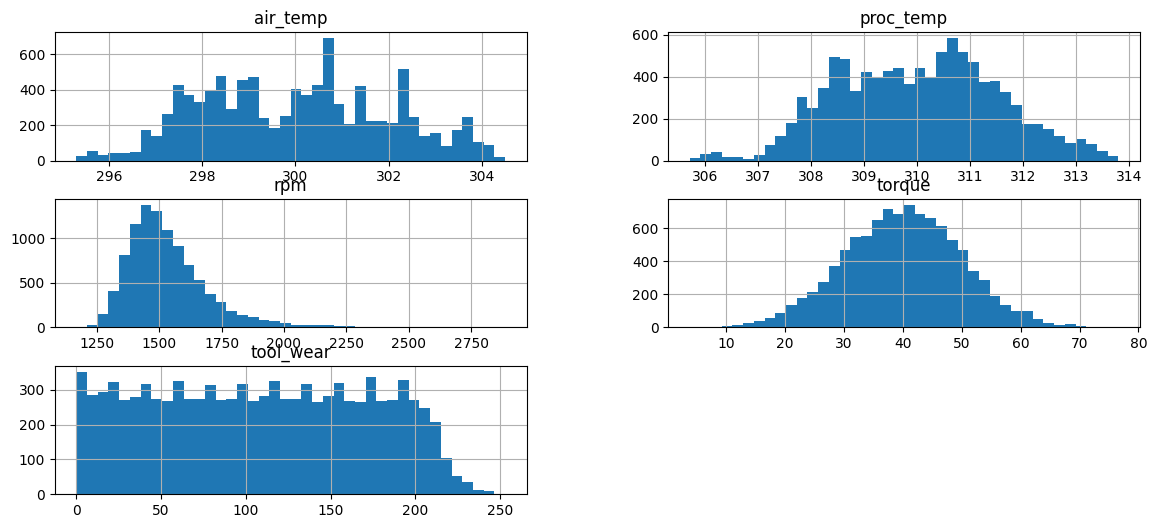

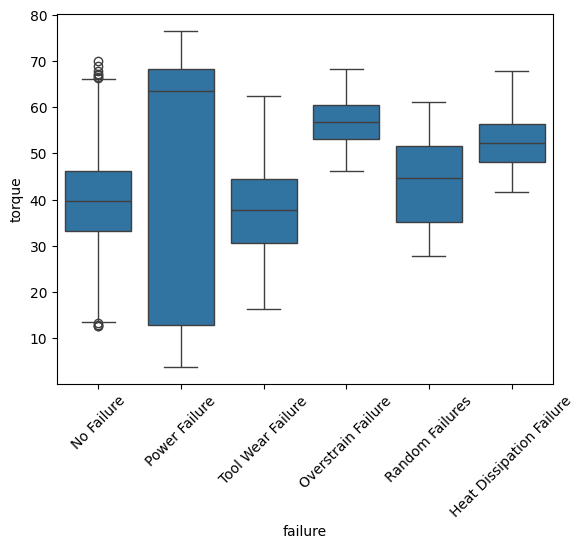

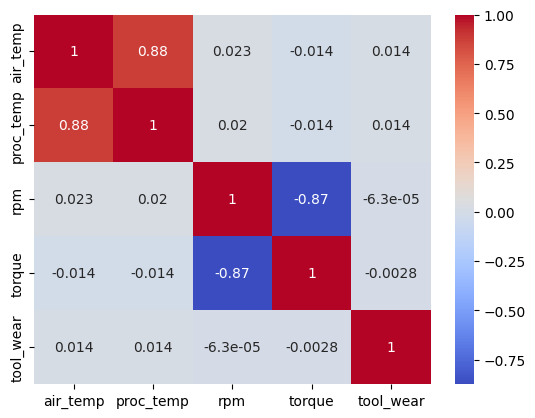

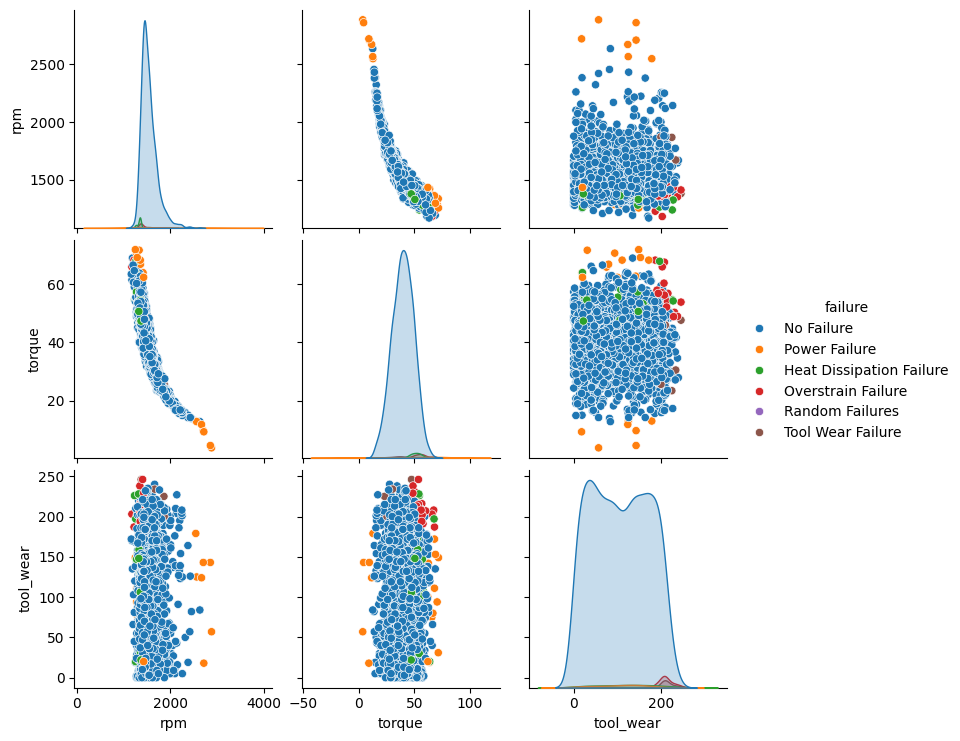

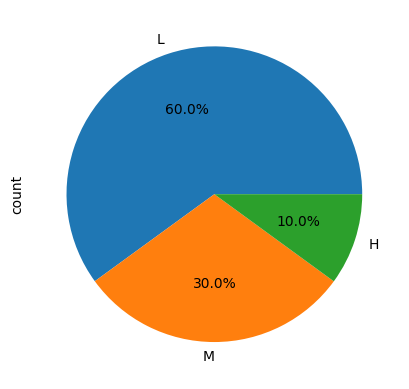

In [20]:
df["failure"].value_counts().plot.bar(title="Distribution des classes"); plt.show()
num = ["air_temp","proc_temp","rpm","torque","tool_wear"]
df[num].hist(bins=40, figsize=(14,6)); plt.show()
sns.boxplot(data=df, x="failure", y="torque"); plt.xticks(rotation=45); plt.show()
sns.heatmap(df[num].corr(), annot=True, cmap="coolwarm"); plt.show()
sns.pairplot(df.sample(2000, random_state=42), hue="failure", vars=["rpm","torque","tool_wear"]); plt.show()
df["Type"].value_counts().plot.pie(autopct="%1.1f%%"); plt.show()

In [21]:
le = LabelEncoder(); y = le.fit_transform(df["failure"])
X = pd.get_dummies(df.drop(columns="failure"), columns=["Type"], dtype=float)
print(le.classes_, X.shape)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sc = StandardScaler().fit(X_tr[num])
X_tr = X_tr.copy(); X_te = X_te.copy()
X_tr[num] = sc.transform(X_tr[num]); X_te[num] = sc.transform(X_te[num])

['Heat Dissipation Failure' 'No Failure' 'Overstrain Failure'
 'Power Failure' 'Random Failures' 'Tool Wear Failure'] (9991, 8)


Avant : [  90 7714   62   76   14   36]
Après : [7714 7714 7714 7714 7714 7714]


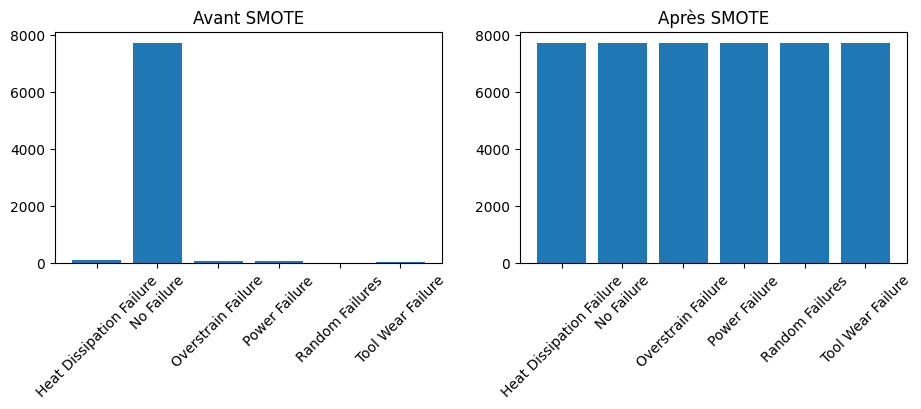

In [22]:
from imblearn.over_sampling import SMOTE
print("Avant :", np.bincount(y_tr))
X_tr_b, y_tr_b = SMOTE(k_neighbors=3, random_state=42).fit_resample(X_tr, y_tr)
print("Après :", np.bincount(y_tr_b))

fig, ax = plt.subplots(1,2, figsize=(11,3))
ax[0].bar(le.classes_, np.bincount(y_tr)); ax[0].set_title("Avant SMOTE")
ax[1].bar(le.classes_, np.bincount(y_tr_b)); ax[1].set_title("Après SMOTE")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.savefig("/kaggle/working/images/p2_smote.png", bbox_inches="tight"); plt.show()

# Conversion en tableaux numpy pour PyTorch
X_tr_np  = X_tr.values.astype("float32");   y_tr_np = y_tr.astype("int64")
X_tr_bnp = X_tr_b.values.astype("float32"); y_tr_bnp = y_tr_b.astype("int64")
X_te_np  = X_te.values.astype("float32");   y_te_np = y_te.astype("int64")

In [23]:
class MLPClf(nn.Module):
    def __init__(self, n_in=8, n_classes=6, hidden=64, n_layers=2, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, dim = [], n_in
        for _ in range(n_layers):
            layers.append(nn.Linear(dim, hidden))
            if batchnorm: layers.append(nn.BatchNorm1d(hidden))
            layers += [nn.ReLU(), nn.Dropout(dropout)]
            dim = hidden
        layers.append(nn.Linear(dim, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

N_IN, N_CLS = X_tr_bnp.shape[1], len(le.classes_)

In [24]:
   from skorch import NeuralNetClassifier

In [25]:
from skorch import NeuralNetClassifier

net = NeuralNetClassifier(MLPClf, module__n_in=N_IN, module__n_classes=N_CLS,
        criterion=nn.CrossEntropyLoss, optimizer=torch.optim.Adam, max_epochs=30,
        batch_size=128, lr=1e-3, device=device, verbose=0, train_split=None)
params = {
    "lr": [1e-2, 1e-3],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [30, 60],
    "module__hidden": [32, 64, 128],
    "module__n_layers": [2, 3],
    
}
gs = GridSearchCV(net, params, cv=3, scoring="f1_macro", verbose=1)
gs.fit(X_tr_bnp, y_tr_bnp)
print(gs.best_params_, gs.best_score_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits
{'lr': 0.001, 'max_epochs': 60, 'module__hidden': 128, 'module__n_layers': 2, 'optimizer': <class 'torch.optim.adam.Adam'>} 0.9652089896732603


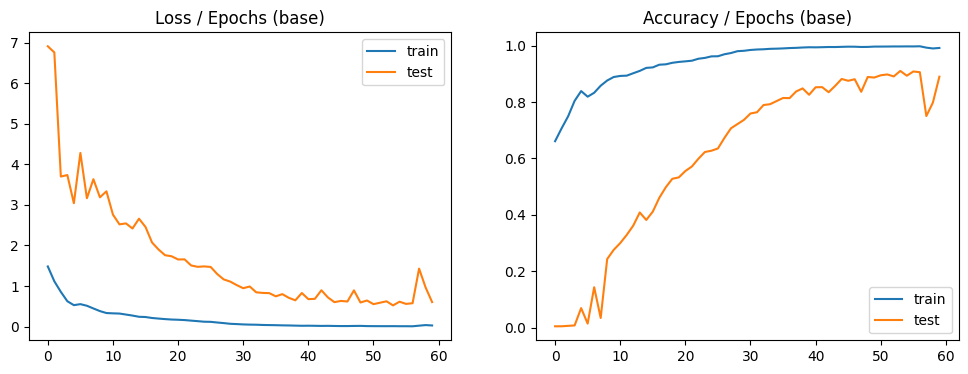

In [26]:
from skorch.callbacks import EpochScoring
from skorch.helper import predefined_split
from skorch.dataset import Dataset

best = {"lr": 0.001, "max_epochs": 60, "module__hidden": 128,
        "module__n_layers": 3, "optimizer": torch.optim.Adam}

def build(**override):
    p = {**best, **override}
    return NeuralNetClassifier(MLPClf, module__n_in=N_IN, module__n_classes=N_CLS,
        criterion=nn.CrossEntropyLoss, device=device, batch_size=128, verbose=0,
        train_split=predefined_split(Dataset(X_te_np, y_te_np)),
        callbacks=[EpochScoring("accuracy", name="train_acc", on_train=True)], **p)

def plot_hist(net, title, fn):
    h = net.history
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    ax[0].plot(h[:,"train_loss"], label="train"); ax[0].plot(h[:,"valid_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs ({title})"); ax[0].legend()
    ax[1].plot(h[:,"train_acc"], label="train"); ax[1].plot(h[:,"valid_acc"], label="test")
    ax[1].set_title(f"Accuracy / Epochs ({title})"); ax[1].legend()
    plt.savefig(f"/kaggle/working/images/{fn}.png"); plt.show()

net_base = build(); net_base.fit(X_tr_bnp, y_tr_bnp)
plot_hist(net_base, "base", "p2_base")

=== Base / TRAIN ===
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.39      0.99      0.56        90
              No Failure       1.00      0.91      0.95      7714
      Overstrain Failure       0.30      1.00      0.47        62
           Power Failure       0.52      1.00      0.69        76
         Random Failures       0.12      1.00      0.21        14
       Tool Wear Failure       0.12      1.00      0.22        36

                accuracy                           0.91      7992
               macro avg       0.41      0.98      0.52      7992
            weighted avg       0.98      0.91      0.94      7992



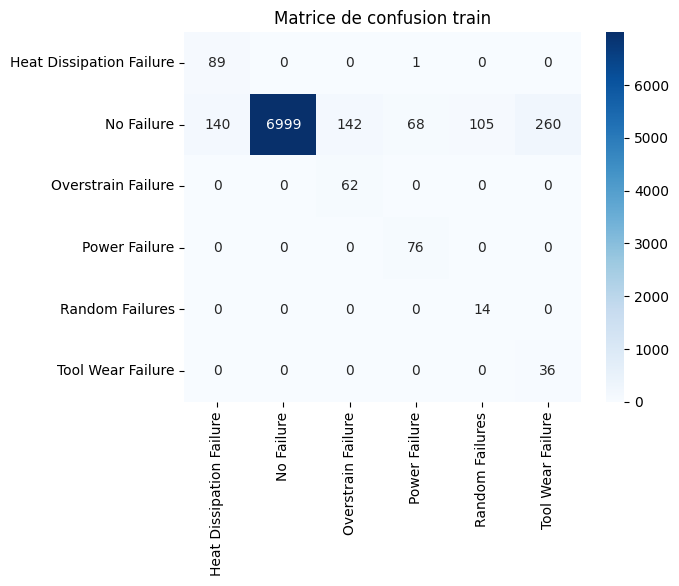

=== Base / TEST ===
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.36      1.00      0.53        22
              No Failure       0.99      0.89      0.94      1929
      Overstrain Failure       0.28      1.00      0.44        16
           Power Failure       0.46      0.95      0.62        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.03      0.22      0.05         9

                accuracy                           0.89      1999
               macro avg       0.35      0.68      0.43      1999
            weighted avg       0.97      0.89      0.92      1999



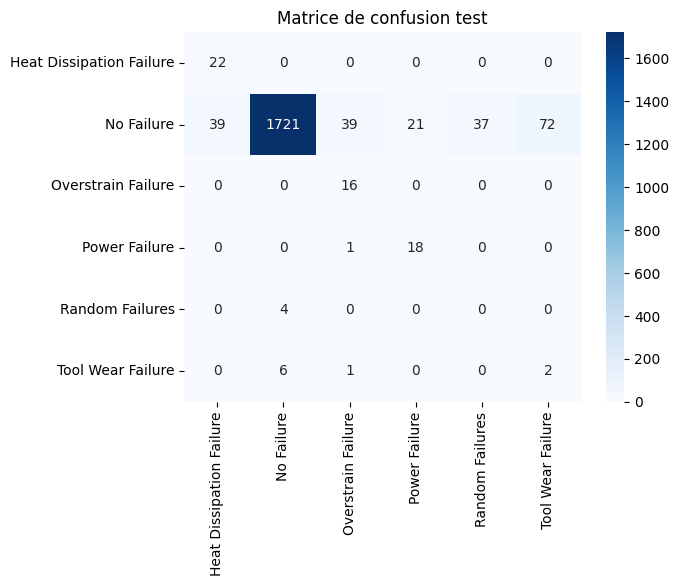

,modèle,acc_train,precision_train,recall_train,f1_macro_train,f1_weighted_train,acc_test,precision_test,recall_test,f1_macro_test,f1_weighted_test
0,Base,0.91041,0.409329,0.9827,0.515123,0.936095,0.889945,0.354024,0.67696,0.429633,0.922965


In [27]:
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, recall_score, precision_score)

def evaluate(net, name, show=True):
    row = {"modèle": name}
    for nm, Xs, ys in [("train", X_tr_np, y_tr_np), ("test", X_te_np, y_te_np)]:
        yp = net.predict(Xs)
        row[f"acc_{nm}"] = accuracy_score(ys, yp)
        row[f"precision_{nm}"] = precision_score(ys, yp, average="macro", zero_division=0)
        row[f"recall_{nm}"] = recall_score(ys, yp, average="macro", zero_division=0)
        row[f"f1_macro_{nm}"] = f1_score(ys, yp, average="macro", zero_division=0)
        row[f"f1_weighted_{nm}"] = f1_score(ys, yp, average="weighted", zero_division=0)
        if show:
            print(f"=== {name} / {nm.upper()} ===")
            print(classification_report(ys, yp, labels=range(N_CLS), target_names=le.classes_, zero_division=0))
            sns.heatmap(confusion_matrix(ys, yp, labels=range(N_CLS)), annot=True, fmt="d",
                        xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
            plt.title(f"Matrice de confusion {nm}"); plt.show()
    return row

results = [evaluate(net_base, "Base")]
pd.DataFrame(results)

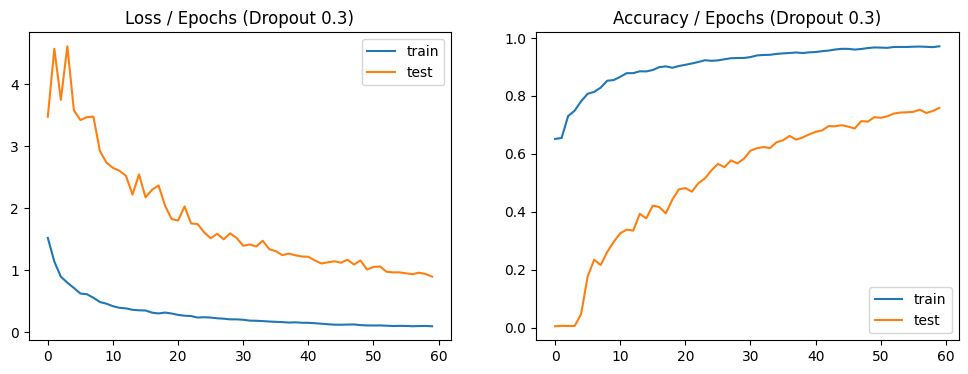

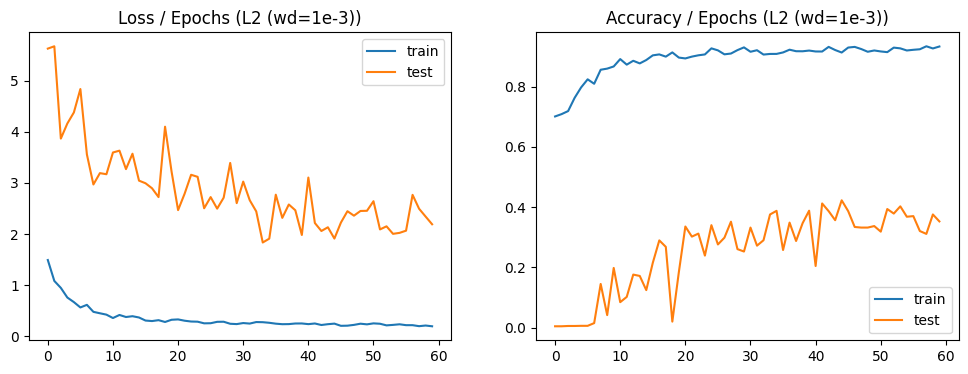

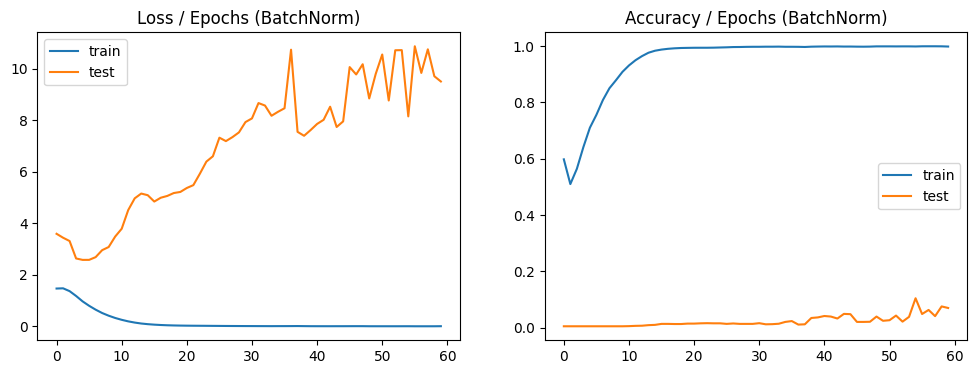

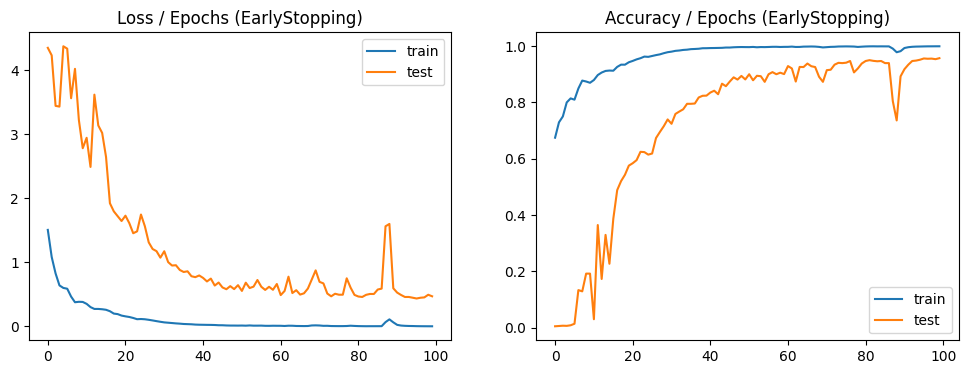

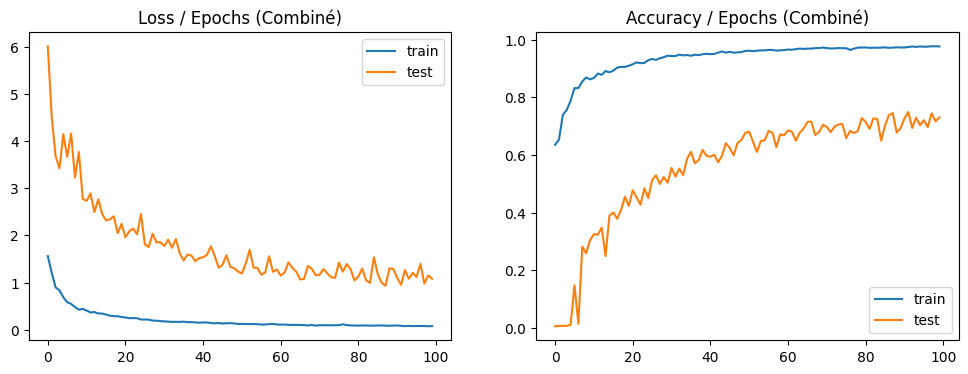

,modèle,acc_train,precision_train,recall_train,f1_macro_train,f1_weighted_train,acc_test,precision_test,recall_test,f1_macro_test,f1_weighted_test
0,Base,0.910410,0.409329,0.982700,0.515123,0.936095,0.889945,0.354024,0.676960,0.429633,0.922965
1,Dropout 0.3,0.784910,0.299268,0.901967,0.360284,0.857001,0.758879,0.288977,0.692384,0.338988,0.840033
2,L2 (wd=1e-3),0.365741,0.219078,0.567376,0.174580,0.515497,0.352676,0.237151,0.533608,0.200823,0.499053
3,BatchNorm,0.066191,0.193130,0.284211,0.039777,0.106156,0.069535,0.232345,0.339172,0.079864,0.108952
4,EarlyStopping,0.986236,0.794358,0.997623,0.867171,0.988149,0.956978,0.443122,0.582489,0.493432,0.962770
5,Combiné,0.756131,0.293126,0.898894,0.348573,0.838410,0.730365,0.291260,0.750245,0.342932,0.820836


In [28]:
from skorch.callbacks import EarlyStopping

configs = {
    "Dropout 0.3":   dict(module__dropout=0.3),
    "L2 (wd=1e-3)":  dict(optimizer__weight_decay=1e-3),
    "BatchNorm":     dict(module__batchnorm=True),
    "EarlyStopping": dict(max_epochs=100, callbacks__early=EarlyStopping(patience=5)),
    "Combiné":       dict(module__dropout=0.2, optimizer__weight_decay=1e-4, max_epochs=100,
                          callbacks__early=EarlyStopping(patience=5)),
}
for name, kw in configs.items():
    n = build(**kw); n.fit(X_tr_bnp, y_tr_bnp)
    plot_hist(n, name, "p2_" + name.split()[0])
    results.append(evaluate(n, name, show=False))

res = pd.DataFrame(results); res.to_csv("/kaggle/working/p2_resultats.csv", index=False)
res